# The University of Azad Jammu and Kashmir
### Department of Software Engineering
**Digital Image Processing Lab** — Lab Instructor: Engr. Fahad Nisar
Semester: Fifth | Session: 2024-28 (SE)

**Name:** Jawahir Ali  |  **Roll No:** 2024-SE-34

---
## Lab Task # 05 – Spatial Filtering and Convolution
Assigned: Nov 13, 2026 | Due: Nov 20, 2026, 11:59 PM

**Objective:** implement 2-D convolution from first principles, then apply mean, Gaussian and median filters to noisy images, checking hand calculations and comparing against OpenCV.

**Rules followed throughout:** R1 same-size output, reflect padding · R2 float64 maths, round + clip to uint8 only at the end · R3 smoothing kernels sum to 1 · R4 odd kernel sizes only · R5 noise uses `seed=5` · R6 every result is judged against the **clean original**.

## 1. Setup and test images
Camera, coins and chelsea (converted to grayscale) from `skimage.data`. The originals are made read-only and a copy is kept so we can prove at the end that they were never modified.

numpy 2.5.3 | opencv 5.0.0 | scikit-image 0.26.0
camera   shape=(512, 512) dtype=uint8 min=0 max=255
coins    shape=(303, 384) dtype=uint8 min=1 max=252
chelsea  shape=(300, 451) dtype=uint8 min=4 max=194


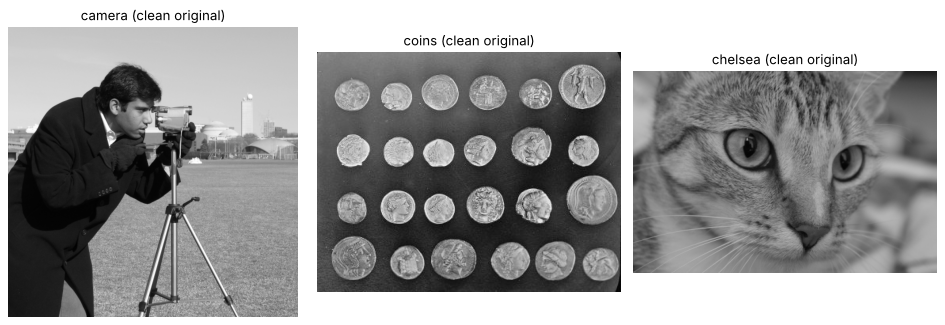

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import skimage
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

print("numpy", np.__version__, "| opencv", cv2.__version__, "| scikit-image", skimage.__version__)

camera  = data.camera()                                              # already grayscale uint8
coins   = data.coins()                                               # already grayscale uint8
chelsea = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY)           # colour -> grayscale uint8

originals = {"camera": camera, "coins": coins, "chelsea": chelsea}
backup = {k: v.copy() for k, v in originals.items()}                 # for the final "unchanged" check
for v in originals.values():
    v.flags.writeable = False                                        # any accidental in-place edit now raises an error

for k, v in originals.items():
    print(f"{k:8s} shape={v.shape} dtype={v.dtype} min={v.min()} max={v.max()}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (k, v) in zip(ax, originals.items()):
    a.imshow(v, cmap="gray", vmin=0, vmax=255); a.set_title(f"{k} (clean original)"); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Convolution from first principles — `conv2d_loop`
True convolution flips the kernel in both directions before the sliding weighted sum:

$$g(i,j)=\sum_{u}\sum_{v} f(i+u-c_y,\, j+v-c_x)\, k_{\text{flipped}}(u,v)$$

Implementation choices (matching the rules):
* **R1** – borders are padded with `np.pad(..., mode="reflect")`, so the output is the same size as the input.
* **R2** – all arithmetic is `float64`; the function returns `float64`. A separate helper `to_uint8` rounds and clips, used only at the very end.
* **R4** – an even kernel size is rejected with a `ValueError`.

In [2]:
def check_odd_kernel(kernel):
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError(f"Kernel size must be odd, got {kh}x{kw}  (R4)")

def conv2d_loop(img, kernel):
    """True 2-D convolution with nested pixel loops.
    flips kernel, reflect-pads borders, float64 weighted sums, same-size float64 output."""
    kernel = np.asarray(kernel, dtype=np.float64)
    check_odd_kernel(kernel)
    img = np.asarray(img, dtype=np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")        # reflect padding (R1)
    flipped = kernel[::-1, ::-1]                                      # flip both axes -> convolution, not correlation
    out = np.zeros(img.shape, dtype=np.float64)
    H, W = img.shape
    for i in range(H):
        for j in range(W):
            window = padded[i:i + kh, j:j + kw]
            out[i, j] = np.sum(window * flipped)                      # weighted sum in float64
    return out

def to_uint8(x):
    """Only used at the very end (R2): round, clip to 0-255, cast."""
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)

# tiny sanity test: an impulse convolved with an asymmetric kernel must reproduce the kernel itself (flip check)
impulse = np.zeros((5, 5)); impulse[2, 2] = 1
asym = np.arange(1, 10, dtype=np.float64).reshape(3, 3)
print(conv2d_loop(impulse, asym)[1:4, 1:4])
print("impulse response equals kernel (true convolution):", np.array_equal(conv2d_loop(impulse, asym)[1:4, 1:4], asym))

[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
impulse response equals kernel (true convolution): True


### 2.1 Verification against OpenCV on a real image
`cv2.filter2D` performs *correlation*, so to mimic true convolution we give it the kernel flipped with `cv2.flip(kernel, -1)`. OpenCV's default border mode `BORDER_REFLECT_101` is identical to NumPy's `"reflect"`. We compare in float64 (exact test) and in uint8 (what you would actually see).

In [3]:
import time
mean3  = np.full((3, 3), 1 / 9)
gauss3 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
asym_k = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=np.float64) / 4   # Sobel-like, NOT symmetric

def cv_conv(img, kernel):
    return cv2.filter2D(img.astype(np.float64), cv2.CV_64F, cv2.flip(kernel, -1), borderType=cv2.BORDER_REFLECT_101)

t = time.time()
rows = []
for name, k in [("mean 3x3", mean3), ("gaussian 3x3", gauss3), ("asymmetric 3x3", asym_k)]:
    mine = conv2d_loop(camera, k)
    ref = cv_conv(camera, k)
    rows.append((name, np.abs(mine - ref).max()))
print(f"(three 512x512 loop convolutions took {time.time()-t:.1f} s)\n")
for name, d in rows:
    print(f"camera, {name:15s}: max |conv2d_loop - OpenCV| (float64) = {d:.3e}")

# Why the flip matters: correlation (no flip) of the asymmetric kernel disagrees badly
corr = cv2.filter2D(camera.astype(np.float64), cv2.CV_64F, asym_k, borderType=cv2.BORDER_REFLECT_101)
print(f"\nasymmetric kernel WITHOUT flip (correlation) vs my convolution: max diff = {np.abs(corr - conv2d_loop(camera, asym_k)).max():.1f}")

# 8-bit comparison for the mean filter: my loop vs cv2.blur
mine_u8 = to_uint8(conv2d_loop(camera, mean3))
cv_u8 = cv2.blur(camera, (3, 3))
diff = np.abs(mine_u8.astype(int) - cv_u8.astype(int))
print(f"\nmean 3x3 on camera, uint8 results: LARGEST DIFFERENCE = {diff.max()} grey level(s); pixels that differ = {(diff>0).sum()} of {diff.size}")

(three 512x512 loop convolutions took 1.8 s)

camera, mean 3x3       : max |conv2d_loop - OpenCV| (float64) = 5.684e-14
camera, gaussian 3x3   : max |conv2d_loop - OpenCV| (float64) = 0.000e+00
camera, asymmetric 3x3 : max |conv2d_loop - OpenCV| (float64) = 0.000e+00

asymmetric kernel WITHOUT flip (correlation) vs my convolution: max diff = 430.0

mean 3x3 on camera, uint8 results: LARGEST DIFFERENCE = 0 grey level(s); pixels that differ = 0 of 262144


## 3. Noise generation (R5: `seed=5`)
Both generators build their own `numpy.random.default_rng(seed)`, so the same call always gives the same noise. Gaussian noise is added in float64, then rounded/clipped; salt-and-pepper sets a random `amount` of pixels, half to 0 (pepper) and half to 255 (salt).

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, img.shape)    # float64 maths (R2)
    return to_uint8(noisy)                                                # round + clip only at the end

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    r = rng.random(img.shape)
    noisy[r < amount / 2] = 0                    # pepper
    noisy[r >= 1 - amount / 2] = 255             # salt
    return noisy

def make_noisy():
    out = {}
    for name, im in originals.items():
        out[f"{name} + gaussian"]     = add_gaussian_noise(im, sigma=20, seed=5)
        out[f"{name} + salt&pepper"]  = add_salt_pepper(im, amount=0.05, seed=5)
    return out

noisy_run1 = make_noisy()
noisy = noisy_run1
print("noisy images created:", list(noisy))

noisy images created: ['camera + gaussian', 'camera + salt&pepper', 'coins + gaussian', 'coins + salt&pepper', 'chelsea + gaussian', 'chelsea + salt&pepper']


In [5]:
# R5: a "fresh run" regenerates everything from scratch with seed=5 -> must be bit-identical
noisy_run2 = make_noisy()
for k in noisy_run1:
    print(f"{k:24s} identical on second run: {np.array_equal(noisy_run1[k], noisy_run2[k])}")
print("All identical:", all(np.array_equal(noisy_run1[k], noisy_run2[k]) for k in noisy_run1))
print("Different seed (sanity, should be False):", np.array_equal(add_gaussian_noise(camera, 20, 5), add_gaussian_noise(camera, 20, 6)))

camera + gaussian        identical on second run: True
camera + salt&pepper     identical on second run: True
coins + gaussian         identical on second run: True
coins + salt&pepper      identical on second run: True
chelsea + gaussian       identical on second run: True
chelsea + salt&pepper    identical on second run: True
All identical: True
Different seed (sanity, should be False): False


### 3.1 Comparison grid: original vs Gaussian noise vs salt-and-pepper

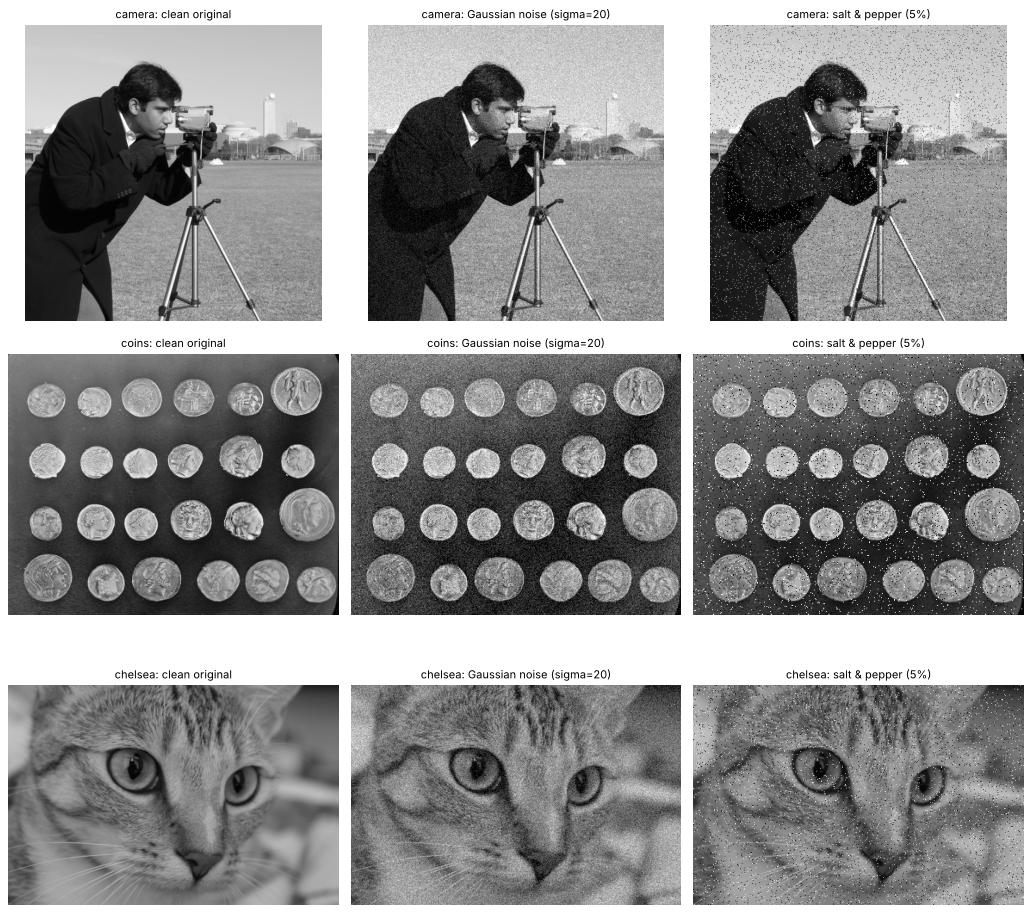

In [6]:
fig, ax = plt.subplots(3, 3, figsize=(13, 12))
for r, (name, im) in enumerate(originals.items()):
    for c, (title, arr) in enumerate([("clean original", im),
                                      ("Gaussian noise (sigma=20)", noisy[f"{name} + gaussian"]),
                                      ("salt & pepper (5%)", noisy[f"{name} + salt&pepper"])]):
        ax[r, c].imshow(arr, cmap="gray", vmin=0, vmax=255)
        ax[r, c].set_title(f"{name}: {title}", fontsize=10); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

## 4. Smoothing kernels and the rules (R3, R4)

In [7]:
def mean_kernel(k):
    return np.full((k, k), 1.0 / (k * k))

def gaussian_kernel(k):
    g = cv2.getGaussianKernel(k, 0)          # the exact 1-D weights cv2.GaussianBlur uses when sigma=0
    return g @ g.T

print("3x3 Gaussian is the 1-2-1 / 16 kernel:", np.allclose(gaussian_kernel(3) * 16, [[1, 2, 1], [2, 4, 2], [1, 2, 1]]))
print()
for k in (3, 5, 7):
    mk, gk = mean_kernel(k), gaussian_kernel(k)
    print(f"{k}x{k}  mean weight sum = {mk.sum():.12f}   gaussian weight sum = {gk.sum():.12f}")
    assert np.isclose(mk.sum(), 1) and np.isclose(gk.sum(), 1)      # R3 enforced before use
print("\nR3 confirmed: every kernel sums to 1.\n")
print("3x3 mean kernel (x9):\n", np.round(mean_kernel(3) * 9))
print("3x3 Gaussian kernel (x16):\n", np.round(gaussian_kernel(3) * 16))
print("5x5 Gaussian kernel (x256):\n", np.round(gaussian_kernel(5) * 256))

3x3 Gaussian is the 1-2-1 / 16 kernel: True

3x3  mean weight sum = 1.000000000000   gaussian weight sum = 1.000000000000
5x5  mean weight sum = 1.000000000000   gaussian weight sum = 1.000000000000
7x7  mean weight sum = 1.000000000000   gaussian weight sum = 1.000000000000

R3 confirmed: every kernel sums to 1.

3x3 mean kernel (x9):
 [[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
3x3 Gaussian kernel (x16):
 [[1. 2. 1.]
 [2. 4. 2.]
 [1. 2. 1.]]
5x5 Gaussian kernel (x256):
 [[ 1.  4.  6.  4.  1.]
 [ 4. 16. 24. 16.  4.]
 [ 6. 24. 36. 24.  6.]
 [ 4. 16. 24. 16.  4.]
 [ 1.  4.  6.  4.  1.]]


In [8]:
# R4: even kernel sizes are rejected
for label, fn in [("cv2.medianBlur(img, 4)", lambda: cv2.medianBlur(camera, 4)),
                  ("my conv2d_loop with a 4x4 kernel", lambda: conv2d_loop(camera[:8, :8], np.ones((4, 4)) / 16))]:
    try:
        fn(); print(label, "-> NOT rejected (unexpected)")
    except Exception as e:
        print(f"{label} -> raised {type(e).__name__}: {str(e).strip().splitlines()[-1][:110]}")

cv2.medianBlur(img, 4) -> raised error: OpenCV(5.0.0) /io/opencv/modules/imgproc/src/median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksi
my conv2d_loop with a 4x4 kernel -> raised ValueError: Kernel size must be odd, got 4x4  (R4)


## 5. Mean, Gaussian and median filters
* **Mean** – `cv2.blur` (fast), and once with my own `conv2d_loop`; the two must agree within rounding.
* **Gaussian** – `cv2.GaussianBlur` with the Gaussian kernel verified above.
* **Median** – `cv2.medianBlur`; even sizes are rejected (R4).

In [9]:
def apply_filter(img, kind, k):
    if k not in (3, 5, 7):
        raise ValueError("Kernel size must be 3, 5 or 7 (odd) - R4")
    if kind == "mean":     return cv2.blur(img, (k, k))
    if kind == "gaussian": return cv2.GaussianBlur(img, (k, k), 0)
    if kind == "median":   return cv2.medianBlur(img, k)
    raise ValueError(kind)

# Mean filter: my conv2d_loop vs cv2.blur on a noisy image, every size
test = noisy["coins + gaussian"]
for k in (3, 5, 7):
    mine = to_uint8(conv2d_loop(test, mean_kernel(k)))
    ref = apply_filter(test, "mean", k)
    d = np.abs(mine.astype(int) - ref.astype(int))
    print(f"mean {k}x{k} on noisy coins: max |conv2d_loop - cv2.blur| = {d.max()} grey level(s)  -> agree within rounding: {d.max() <= 1}")

mean 3x3 on noisy coins: max |conv2d_loop - cv2.blur| = 0 grey level(s)  -> agree within rounding: True
mean 5x5 on noisy coins: max |conv2d_loop - cv2.blur| = 0 grey level(s)  -> agree within rounding: True
mean 7x7 on noisy coins: max |conv2d_loop - cv2.blur| = 0 grey level(s)  -> agree within rounding: True


In [10]:
# R1/R2 compliance check on EVERY filtered output
sizes, kinds = (3, 5, 7), ("mean", "gaussian", "median")
results = {}                                    # results[(noisy_name, kind, k)] = filtered image
bad = 0
for nname, nimg in noisy.items():
    for kind in kinds:
        for k in sizes:
            out = apply_filter(nimg, kind, k)
            results[(nname, kind, k)] = out
            ok = out.dtype == np.uint8 and out.min() >= 0 and out.max() <= 255 and out.shape == nimg.shape
            bad += (not ok)
print(f"checked {len(results)} filtered images (6 noisy x 3 filters x 3 sizes): dtype uint8, range 0-255, same shape as input")
print("all compliant:", bad == 0)

checked 54 filtered images (6 noisy x 3 filters x 3 sizes): dtype uint8, range 0-255, same shape as input
all compliant: True


### 5.1 Grid: mean vs Gaussian vs median (3×3) on every noisy image
The first column is the **clean original** — all judgement is made against it (R6). PSNR (dB, higher is better) is measured against the clean original, never the noisy input.

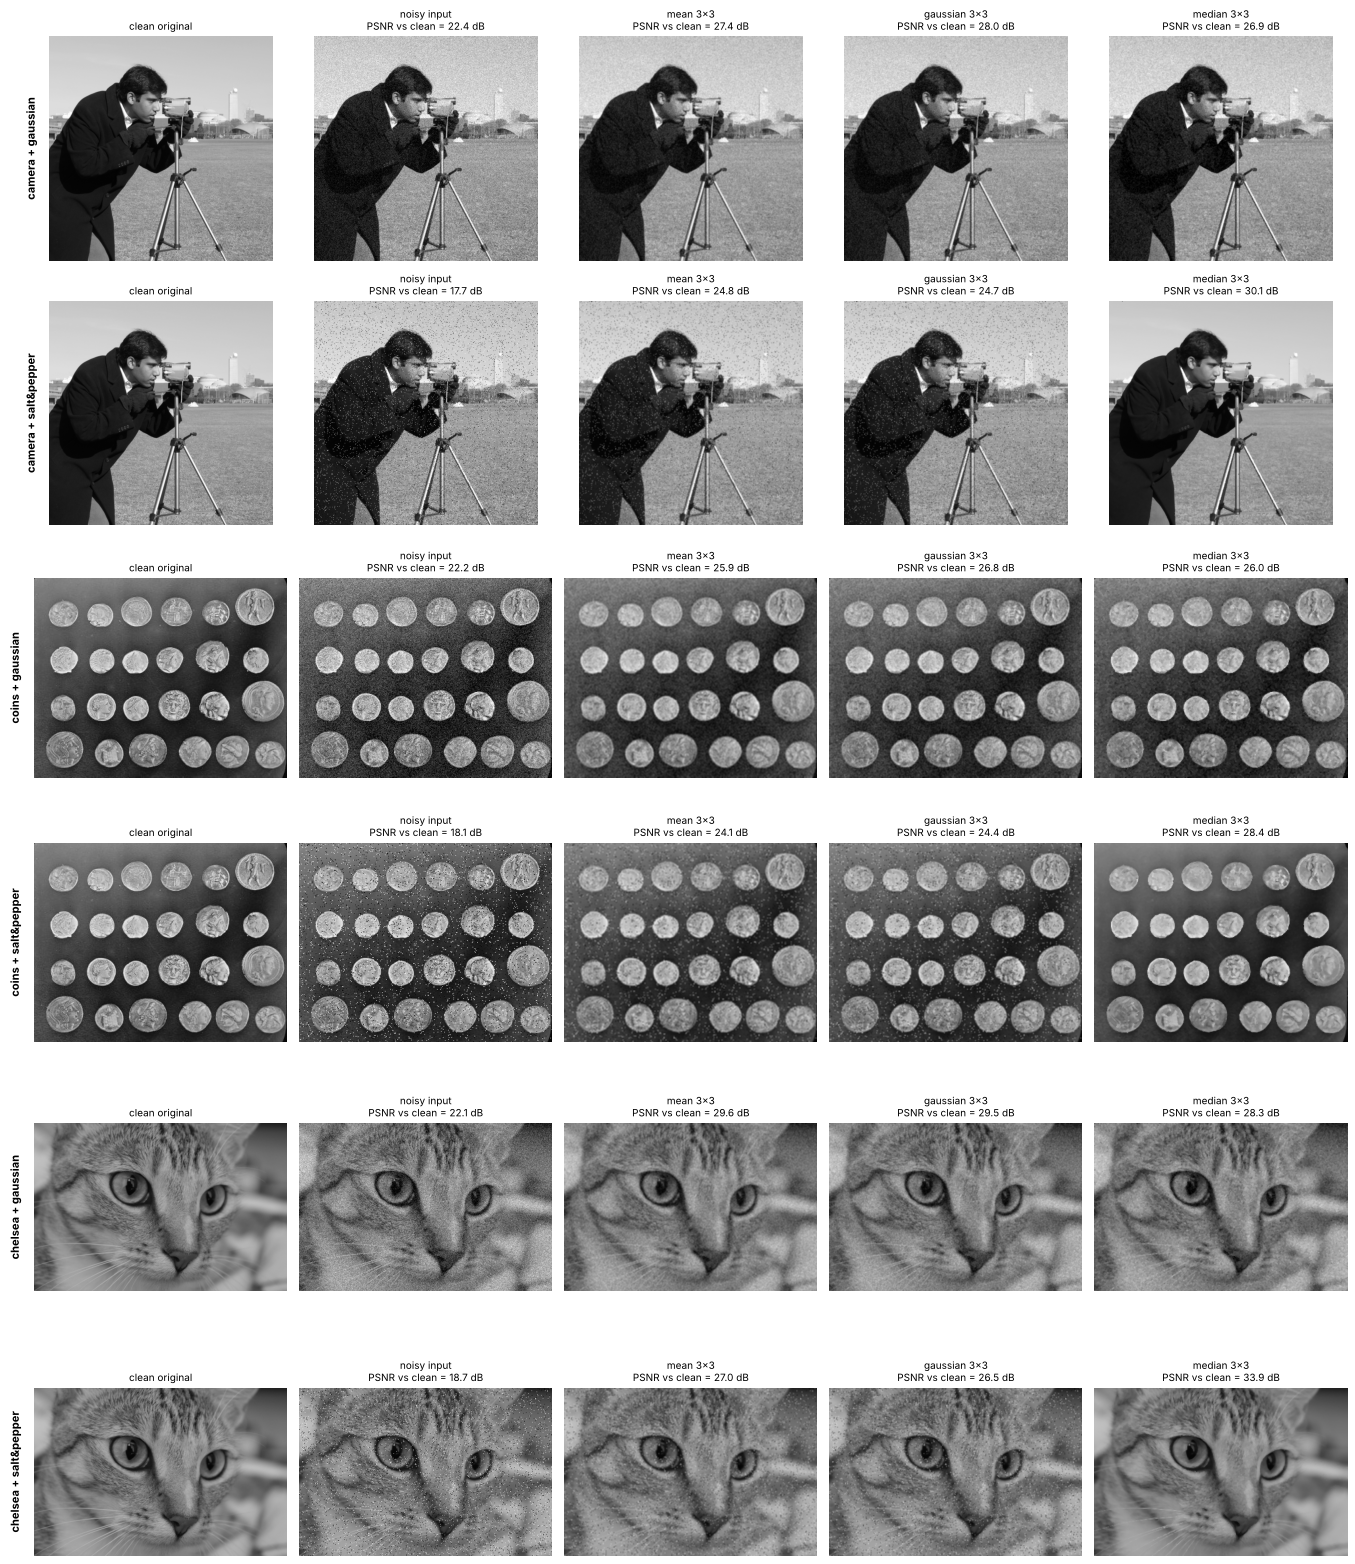

In [11]:
fig, ax = plt.subplots(6, 5, figsize=(17, 20))
for r, (nname, nimg) in enumerate(noisy.items()):
    base = nname.split(" + ")[0]
    clean = originals[base]
    panels = [("clean original", clean), ("noisy input", nimg)] + \
             [(f"{kind} 3x3", results[(nname, kind, 3)]) for kind in kinds]
    for c, (t, arr) in enumerate(panels):
        ax[r, c].imshow(arr, cmap="gray", vmin=0, vmax=255)
        ax[r, c].set_title(t if c == 0 else f"{t}\nPSNR vs clean = {psnr(clean, arr):.1f} dB", fontsize=9)
        ax[r, c].axis("off")
    ax[r, 0].text(-0.05, 0.5, nname, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10, weight="bold")
plt.tight_layout(); plt.show()

### 5.2 Numbers against the clean original (R6)

In [12]:
print(f"{'noisy image':24s} {'noisy':>7s} | {'mean3':>6s} {'gauss3':>6s} {'median3':>7s} | {'mean5':>6s} {'gauss5':>6s} {'median5':>7s} | {'mean7':>6s} {'gauss7':>6s} {'median7':>7s}   (PSNR dB vs CLEAN)")
table = {}
for nname, nimg in noisy.items():
    clean = originals[nname.split(" + ")[0]]
    row = [psnr(clean, nimg)]
    for k in sizes:
        for kind in kinds:
            row.append(psnr(clean, results[(nname, kind, k)]))
    table[nname] = row
    print(f"{nname:24s} {row[0]:7.1f} | " + " | ".join(" ".join(f"{v:{'7' if j==2 else '6'}.1f}" for j, v in enumerate(row[1+3*i:4+3*i])) for i in range(3)))

print()
for noise in ("gaussian", "salt&pepper"):
    names = [n for n in noisy if n.endswith(noise)]
    avg3 = {kind: np.mean([table[n][1 + kinds.index(kind)] for n in names]) for kind in kinds}
    print(f"{noise:12s} average PSNR at 3x3:", {k: round(float(v), 1) for k, v in avg3.items()})

# noisiest image = lowest PSNR of the noisy input vs the clean original
noisiest = min(noisy, key=lambda n: psnr(originals[n.split(' + ')[0]], noisy[n]))
print("\nNoisiest image (lowest PSNR vs clean):", noisiest, f"({psnr(originals[noisiest.split(' + ')[0]], noisy[noisiest]):.1f} dB)")

noisy image                noisy |  mean3 gauss3 median3 |  mean5 gauss5 median5 |  mean7 gauss7 median7   (PSNR dB vs CLEAN)
camera + gaussian           22.4 |   27.4   28.0    26.9 |   26.2   27.8    26.8 |   24.8   27.0    25.8
camera + salt&pepper        17.7 |   24.8   24.7    30.1 |   25.1   25.6    27.8 |   24.3   25.7    26.2
coins + gaussian            22.2 |   25.9   26.8    26.0 |   24.0   26.0    25.4 |   22.8   24.9    24.5
coins + salt&pepper         18.1 |   24.1   24.4    28.4 |   23.4   24.6    26.3 |   22.4   24.0    25.2
chelsea + gaussian          22.1 |   29.6   29.5    28.3 |   29.6   30.4    29.1 |   28.7   30.3    28.7
chelsea + salt&pepper       18.7 |   27.0   26.5    33.9 |   28.3   28.1    31.0 |   28.0   28.8    29.7

gaussian     average PSNR at 3x3: {'mean': 27.6, 'gaussian': 28.1, 'median': 27.1}
salt&pepper  average PSNR at 3x3: {'mean': 25.3, 'gaussian': 25.2, 'median': 30.8}

Noisiest image (lowest PSNR vs clean): camera + salt&pepper (17.7 dB)


### 5.3 Kernel-size grid (filter × kernel size) on the noisiest image

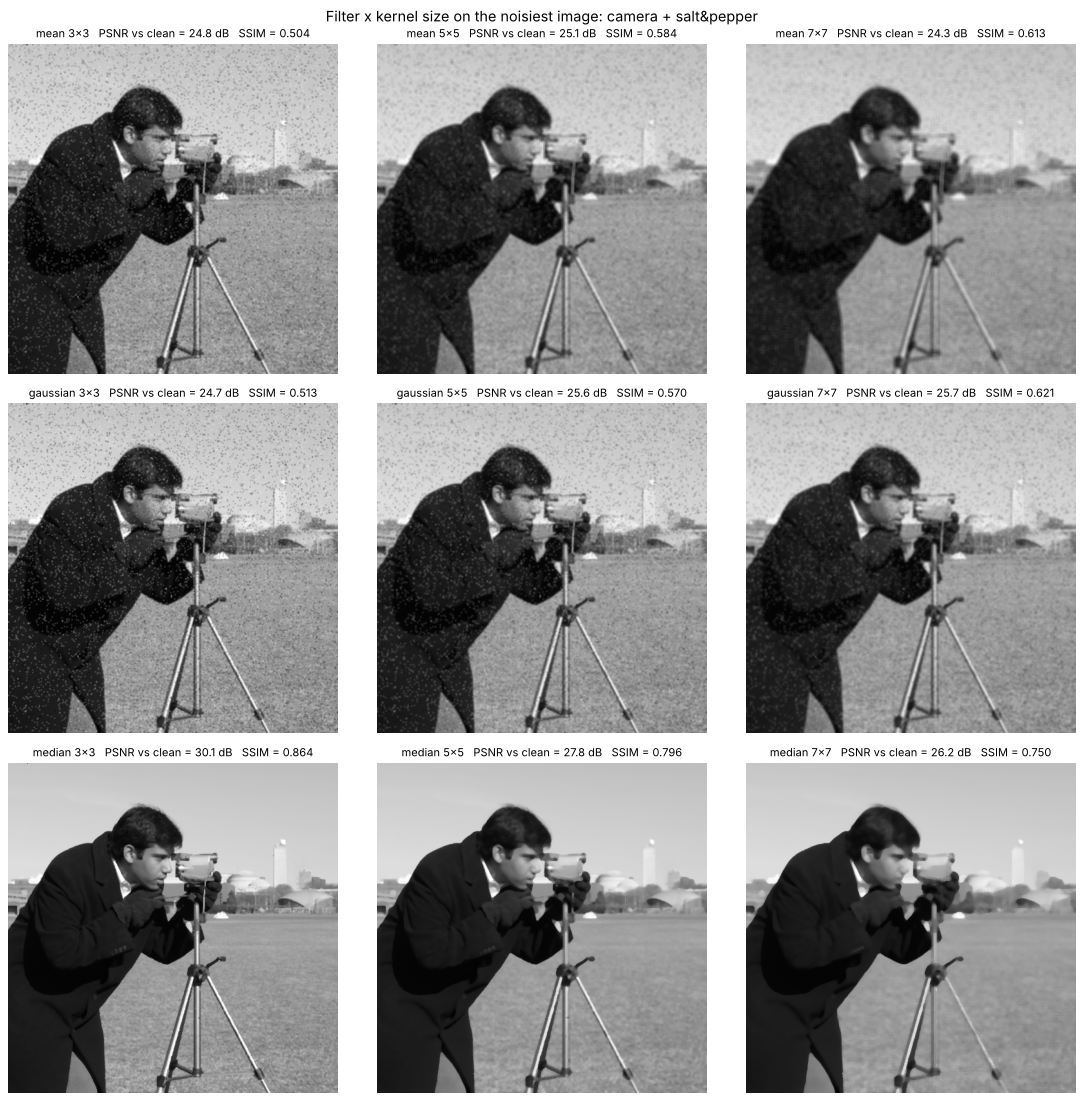

In [13]:
base = noisiest.split(" + ")[0]
clean = originals[base]
fig, ax = plt.subplots(3, 3, figsize=(14, 14))
for r, kind in enumerate(kinds):
    for c, k in enumerate(sizes):
        out = results[(noisiest, kind, k)]
        ax[r, c].imshow(out, cmap="gray", vmin=0, vmax=255)
        ax[r, c].set_title(f"{kind} {k}x{k}   PSNR vs clean = {psnr(clean, out):.1f} dB   SSIM = {ssim(clean, out):.3f}", fontsize=10)
        ax[r, c].axis("off")
fig.suptitle(f"Filter x kernel size on the noisiest image: {noisiest}", fontsize=13)
plt.tight_layout(); plt.show()

### 5.4 Extra evidence for the observations: edge profile and fine-detail crop
To see *only* what each filter does to structure (without the noise getting in the way), the filters are applied to the **clean camera image** and compared to it.

edge located at row 205, between columns 176 and 177
clean         profile: [32, 32, 31, 36, 38, 42, 62, 223, 254, 254, 255]   10-90% rise distance: 1.70 px
mean 3x3      profile: [31, 31, 32, 35, 38, 50, 111, 180, 240, 251, 253]   10-90% rise distance: 2.79 px
gaussian 3x3  profile: [31, 31, 32, 35, 38, 48, 100, 190, 243, 252, 254]   10-90% rise distance: 2.68 px


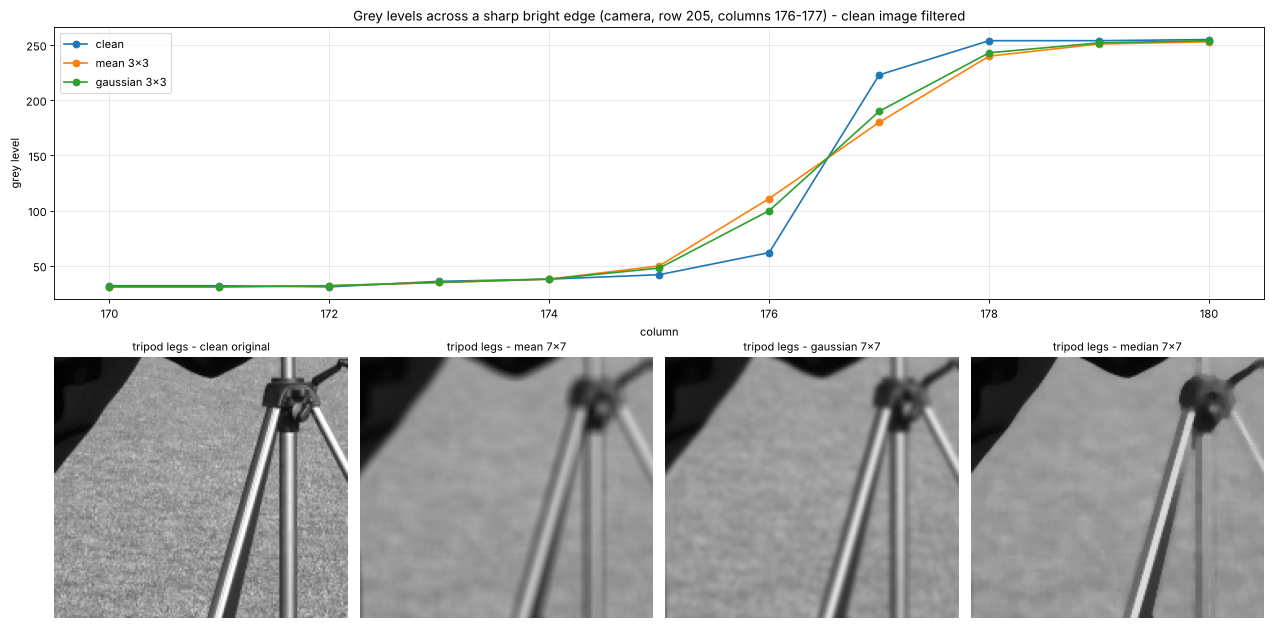

In [14]:
clean = camera
# find a clean step edge: big jump between two flat 6-pixel stretches (low std on both sides), searched over the whole camera image
from numpy.lib.stride_tricks import sliding_window_view
win = sliding_window_view(clean.astype(float), 12, axis=1)            # (rows, cols-11, 12)
L, R = win[..., :6], win[..., 6:]
score = np.abs(R.mean(-1) - L.mean(-1)) - 4 * (L.std(-1) + R.std(-1))
gy, gx = np.unravel_index(np.argmax(score), score.shape)
row, col = gy, gx + 5                                                  # edge between columns col and col+1
sl = slice(col - 6, col + 5)
prof = {"clean": clean[row, sl], "mean 3x3": cv2.blur(clean, (3, 3))[row, sl], "gaussian 3x3": cv2.GaussianBlur(clean, (3, 3), 0)[row, sl]}

def rise_width(p):                         # sub-pixel distance (in pixels) needed to rise from 10% to 90% of the step height
    p = np.maximum.accumulate(p.astype(float)); lo, hi = p[0], p[-1]
    xs = np.arange(len(p))
    return float(np.interp(lo + 0.9 * (hi - lo), p, xs) - np.interp(lo + 0.1 * (hi - lo), p, xs))

print(f"edge located at row {row}, between columns {col} and {col+1}")
for k, v in prof.items():
    print(f"{k:13s} profile: {v.astype(int).tolist()}   10-90% rise distance: {rise_width(v):.2f} px")

fig = plt.figure(figsize=(16, 8))
ax0 = fig.add_subplot(2, 1, 1)
x = np.arange(sl.start, sl.stop)
for k, v in prof.items():
    ax0.plot(x, v, marker="o", label=k)
ax0.set_title(f"Grey levels across a sharp bright edge (camera, row {row}, columns {col}-{col+1}) - clean image filtered"); ax0.set_xlabel("column"); ax0.set_ylabel("grey level"); ax0.legend(); ax0.grid(alpha=.3)

crop = (slice(300, 460), slice(150, 330))      # the tripod legs: thin bright lines on grass
panels = [("clean original", clean), ("mean 7x7", cv2.blur(clean, (7, 7))), ("gaussian 7x7", cv2.GaussianBlur(clean, (7, 7), 0)), ("median 7x7", cv2.medianBlur(clean, 7))]
for c, (t, im) in enumerate(panels):
    a = fig.add_subplot(2, 4, 5 + c); a.imshow(im[crop], cmap="gray", vmin=0, vmax=255); a.set_title(f"tripod legs - {t}", fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

## 6. Dry-run exercises

### Exercise 1 — Spike response
Neighbourhood (centre pixel is a 255 spike among 40s):

$$\begin{bmatrix}40&40&40\\40&255&40\\40&40&40\end{bmatrix}$$

**(a) 3×3 mean kernel** (every weight 1/9):
sum = 8 × 40 + 255 = 320 + 255 = **575**; output = 575 / 9 = 63.89 → **64**

**(b) 3×3 Gaussian kernel** $\frac1{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$:
* corners: (1+1+1+1) × 40 = 4 × 40 = 160
* edges: (2+2+2+2) × 40 = 8 × 40 = 320
* centre: 4 × 255 = 1020
* total = 160 + 320 + 1020 = **1500**; output = 1500 / 16 = 93.75 → **94**

**(c) 3×3 median:** sorted values = 40, 40, 40, 40, 40, 40, 40, 40, 255 → 5th (middle) value = **40**

The mean and Gaussian are dragged towards the spike (64 and 94); the median ignores it completely (40).

In [15]:
win = np.array([[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.float64)
print("Exercise 1 (code):")
print(f"  mean     : sum = {np.sum(win):.0f}  ->  {np.sum(win)/9:.2f}  -> rounded {to_uint8(np.sum(win)/9)}")
print(f"  gaussian : weighted sum = {np.sum(win * np.array([[1,2,1],[2,4,2],[1,2,1]])):.0f}  ->  /16 = {np.sum(win * np.array([[1,2,1],[2,4,2],[1,2,1]]))/16:.2f}  -> rounded {to_uint8(np.sum(win * np.array([[1,2,1],[2,4,2],[1,2,1]]))/16)}")
print(f"  median   : sorted = {[int(v) for v in sorted(win.ravel())]}  ->  {np.median(win):.0f}")
print("Cross-check with my conv2d_loop centre pixel :  mean =", to_uint8(conv2d_loop(win, mean3)[1, 1]), "| gaussian =", to_uint8(conv2d_loop(win, gauss3)[1, 1]))
w8 = win.astype(np.uint8)
print("Cross-check with OpenCV centre pixel         :  mean =", cv2.blur(w8, (3, 3))[1, 1], "| gaussian =", cv2.GaussianBlur(w8, (3, 3), 0)[1, 1], "| median =", cv2.medianBlur(w8, 3)[1, 1])

Exercise 1 (code):
  mean     : sum = 575  ->  63.89  -> rounded 64
  gaussian : weighted sum = 1500  ->  /16 = 93.75  -> rounded 94
  median   : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255]  ->  40
Cross-check with my conv2d_loop centre pixel :  mean = 64 | gaussian = 94
Cross-check with OpenCV centre pixel         :  mean = 64 | gaussian = 94 | median = 40


### Exercise 2 — Reflect padding at a corner
Image:

$$\begin{bmatrix}10&20&30\\40&50&60\\70&80&90\end{bmatrix}$$

For pixel (0, 0) the 3×3 window reaches one row above and one column left of the image. `mode="reflect"` mirrors **without repeating the edge pixel**: the row above row 0 is row 1, and the column left of column 0 is column 1. So the padded neighbourhood of (0, 0) is

$$\begin{bmatrix}50&40&50\\20&10&20\\50&40&50\end{bmatrix}$$

(top-left 50 = image[1,1], top-middle 40 = image[1,0], top-right 50 = image[1,1], left 20 = image[0,1], centre 10, right 20, bottom row 50, 40, 50).

Sum = (50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = **330**
Mean = 330 / 9 = 36.67 → **37**

In [16]:
img3 = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], dtype=np.float64)
padded = np.pad(img3, 1, mode="reflect")
nb = padded[0:3, 0:3]                         # 3x3 neighbourhood of pixel (0,0) in the padded image
print("padded image:\n", padded.astype(int))
print("\nneighbourhood of (0,0):\n", nb.astype(int))
print(f"\nsum = {nb.sum():.0f}, mean = {nb.sum()/9:.4f}  -> rounded {to_uint8(nb.sum()/9)}")
print("my conv2d_loop  [0,0] =", round(conv2d_loop(img3, mean3)[0, 0], 4))
print("cv2.blur        [0,0] =", cv2.blur(img3.astype(np.uint8), (3, 3))[0, 0], "(OpenCV default border BORDER_REFLECT_101 == numpy 'reflect')")

padded image:
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood of (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]

sum = 330, mean = 36.6667  -> rounded 37
my conv2d_loop  [0,0] = 36.6667
cv2.blur        [0,0] = 37 (OpenCV default border BORDER_REFLECT_101 == numpy 'reflect')


## 7. Observations (judged against the clean original — R6)
All numbers are PSNR in dB measured against the **clean original** (sections 5.1–5.4). Higher is better.

**1. Best and worst filter on Gaussian noise.** The **Gaussian filter looks best**: on *camera + gaussian* it reaches 28.0 dB versus 27.4 (mean) and 26.9 (median), and on *coins + gaussian* 26.8 versus 25.9 and 26.0; averaged over the three images at 3×3 it scores 28.1 against 27.6 and 27.1. (On *chelsea + gaussian* it is level with the mean, 29.5 vs 29.6, and pulls ahead at 5×5, 30.4 vs 29.6.) The **median looks worst**: in the *chelsea + gaussian* row the out-of-focus background on the right still looks grainy in the median panel (28.3 dB, the lowest of the three), and on *camera + gaussian* the grass keeps a blotchy mottled texture. Gaussian noise changes *every* pixel a little, so averaging cancels it, while the median just picks one of the noisy values (on *coins + gaussian* the median is only 0.1 dB better than the mean, effectively tied for worst).

**2. Best filter on salt-and-pepper, and why the other two fail.** The **median is by far the best**: *camera + salt&pepper* 30.1 dB vs 24.8 (mean) and 24.7 (Gaussian); *coins + salt&pepper* 28.4 vs 24.1 / 24.4; *chelsea + salt&pepper* 33.9 vs 27.0 / 26.5. In the median panels the black coat and the grass of *camera + salt&pepper* are clean, whereas in the mean and Gaussian panels every black/white dot is still there, only turned into a grey smudge (look at the grass on the right half of the camera image). Mean and Gaussian are *linear*: a spike of 255 or 0 is far from its neighbours, so it still adds its weight to the sum and drags the output toward itself. Dry-run Exercise 1 shows this: one 255 among 40s gives 64 (mean) and 94 (Gaussian, centre weight 4/16) instead of 40. The median sorts the window, the single extreme value lands at the end of the list and is never the middle element, so the output is 40.

**3. Mean vs Gaussian on a sharp edge.** In the profile figure of section 5.4 (camera, row 205, columns 176–177) the clean edge jumps from 62 to 223 in one pixel. After 3×3 filtering the mean gives 111 → 180 and the Gaussian gives 100 → 190, i.e. the Gaussian keeps the step steeper (10–90 % rise distance 2.68 px vs 2.79 px for the mean). The reason is the weights: the Gaussian puts 4/16 = 0.25 on the centre pixel and only 1/16 on the corners, while the mean gives every pixel 1/9 ≈ 0.11, so it mixes in more of the other side of the edge. At 3×3 the difference is small, but it is consistent, and the same ordering shows in the 7×7 tripod crop where the mean looks a little softer than the Gaussian.

**4. What happens to fine detail at 7×7.** It is lost. In the tripod crop of section 5.4 the fine grass texture is completely gone in mean 7×7 and Gaussian 7×7 and the thin metal legs turn into wide, fuzzy grey bands; the median 7×7 keeps the legs' edges but the thin vertical centre leg becomes dim and broken and the tripod head turns into a blob. In the kernel-size grid on *camera + salt&pepper* the median's PSNR falls with every step (30.1 → 27.8 → 26.2 dB) and its SSIM falls (0.864 → 0.796 → 0.750) as the tower and the camera lens lose their shape. Mean and Gaussian PSNR rise a little on this image (e.g. Gaussian 24.7 → 25.7) only because bigger windows dilute the spikes more, but the image is visibly blurrier, so larger is not better.

**5. Why the kernel size must be odd.** A kernel needs a single centre pixel so that the output lands exactly on the input pixel it belongs to. In the 3×3 window of Exercise 1 the 255 sits at the exact centre with one pixel on every side; a 4×4 window has no centre, so the result would be shifted by half a pixel and padding would have to be uneven. An odd size k also needs exactly (k−1)/2 padding pixels on each side (1 for 3×3 in Exercise 2), which keeps the output the same size as the input (R1). A median also needs an odd number of values to have one middle element; with 16 values there would be two. OpenCV enforces this: `cv2.medianBlur(img, 4)` raised an assertion error in section 4, and my `conv2d_loop` raises `ValueError` for a 4×4 kernel (R4).

## 8. Viva preparation (two questions)

**Q: Why does the median remove a 255 spike but the mean does not?**
The mean adds up all nine values, so the spike contributes its full amount: in Exercise 1, (8×40 + 255) / 9 = 63.9 → 64, a pixel that was supposed to be about 40 is still clearly brighter. The median sorts the nine values (40 ×8, then 255); the spike always ends up at the very end of the sorted list, never at the middle (5th) position, so the output is 40 and the spike has no influence at all. The median can only be fooled when *more than half* of the window is corrupted.

**Q: Why do the Gaussian weights sum to 16, and why divide by it?**
The 3×3 Gaussian is the outer product of the 1-D binomial weights [1, 2, 1] with itself: [[1,2,1],[2,4,2],[1,2,1]]. Adding them gives 1+2+1+2+4+2+1+2+1 = 16 (4 × 4 from the 1-D sums). Dividing by 16 makes the weights add up to 1 (rule R3), so a flat region keeps its brightness: a flat patch of 40 gives 40 × 16 / 16 = 40. Without the division the same patch would give 640 and everything would saturate to 255.

## 9. Final check — originals were never modified

In [17]:
for k in originals:
    print(f"{k:8s} unchanged: {np.array_equal(originals[k], backup[k])}")

camera   unchanged: True
coins    unchanged: True
chelsea  unchanged: True
